# eSCALE × DES Y3: selection-modelled $L_X$–$M$ fits

Follows `lx_selection_modelling.ipynb`, which introduces the selection model. Scripts: `scripts/lx/fit_escale_sel.py` and `scripts/lx/make_escale_mock.py`, on branch `lx_erosita_splus`.

**Notation.**
- **Indices:** $c$ labels a cluster, $s$ a stack, and $k$ a point of the mass grid $\log M_k$ (61 points from 11.8 to 15.8 in $\log_{10}M_{200c}$).
- **Relation and parameters:** $\theta = (\alpha, \beta, \gamma, \sigma_{\rm int}, f_{\rm mis}, \sigma_{\rm off})$.
  - $\alpha, \beta, \gamma$ are the normalisation, mass slope and redshift term of the Pederneiras+25 relation $\log_{10}[L_XE(z)^{-1}/L_{\rm piv}] = \alpha + \beta\log_{10}[M_{200c}E(z)/M_{\rm piv}] + \gamma\log_{10}[(1+z)/(1+z_{\rm piv})]$, with $L_{\rm piv} = 10^{43.26}$ erg/s, $M_{\rm piv} = 10^{14.1}$ M$_\odot$, $z_{\rm piv} = 0.18$.
  - $\sigma_{\rm int}$ is the log-normal intrinsic scatter of $\log_{10}L_X$ at fixed mass [dex].
  - $f_{\rm mis}$ is the fraction of miscentred clusters, whose offsets from the X-ray centre follow a Rayleigh distribution of scale $\sigma_{\rm off}$ [Mpc].
- **X-ray measurement:** $\hat F_c$ and $\sigma_{F,c}$ are cluster $c$'s measured 0.6–2.3 keV flux and its error. $\kappa_c = L_{X,c}/\hat F_c$ is its luminosity-to-flux conversion from the catalogue (K-correction, aperture, $N_H$).
- **Mass prior:** $w_{ck}(\theta) = P(\log M_k\mid\text{cluster }c\text{'s data, selected}, \theta)$, normalised so that $\sum_k w_{ck} = 1$:
$$w_{ck}(\theta)\propto\frac{dn}{d\log M}(M_k,z_c)\int d\log L\;\mathcal N(\log L;\langle\log L_X\mid M_k,z_c\rangle,\sigma_{\rm int})\;\mathcal N(\hat F_c;L/\kappa_c,\sigma_{F,c})\;\big[\times P(\text{optical detection}\mid M_k,z_c,\hat F_c)\big].$$
  The first factor is the halo mass function (Tinker+08).
- **Stacks:** $K_c(R)=\sum_{\rm sources}(1+m)\,w/\Sigma_{\rm crit}^2$ is cluster $c$'s lensing weight in radial bin $R$, the same weight the stacked measurement uses.

**Selection variants.**
- **A**: only the X-ray stage (flux S/N ≥ 2). It depends on measured quantities only, so it cancels. The bracket in $w_{ck}$ is absent.
- **A+B**: A plus the optical detection stage, which depends on richness, which is not modelled, so it does not cancel (the bracket). Its richness–mass relation and threshold are **assumed placeholders** until the S-PLUS side provides the real optical selection.
- A alone is known to be invalid for eSCALE (see `lx_selection_modelling.ipynb`). All results below are A+B.

**The three frameworks.**

| Framework | Model |
|---|---|
| joint | $\ln\mathcal L=\sum_c\ln\sum_k w_{ck}\,\mathcal L_c(\Delta\Sigma_c\mid M_k)$, per-bin Sellentin–Heavens likelihood |
| forward-modelled stacks | stack model $\Delta\Sigma_s=\sum_{c\in s}K_c\sum_k w_{ck}\Delta\Sigma_{ck}/\sum_{c\in s}K_c$, Sellentin–Heavens likelihood with $N$ = member clusters |
| two-step | each stack is first fitted for a single mass; those masses are then compared with the model's lensing-weighted mean mass of each stack |

**Samples.**
- **full:** 1556 clusters.
- **p90 / p95:** the 1024 / 496 clusters that SCALE II's matching keeps at 90% / 95% purity (catalogue flags `p90`, `p95`).

The subsets have their own stacks: 3 × 5 (redshift × $L_X$) for p90 and 2 × 3 for p95, keeping at least 50 clusters per stack.

**Mocks.** 10 eSCALE-like realisations with real DES Y3 lensing noise: each mock cluster borrows the background sources of a real eSCALE cluster at the same redshift, and the real cross shear is the noise. Truth: $\alpha = 0.47$, $\beta = 1.11$, $\gamma = 0$, $\sigma_{\rm int} = 0.17$, $f_{\rm mis} = 0.3$, $\sigma_{\rm off} = 0.15$ Mpc, with the same assumed optical selection as A+B. Haloes are spherical NFW, and miscentring enters as the mean mixture profile; there is no triaxiality and no per-cluster offset.

In [1]:
import numpy as np, json, glob, os
import matplotlib.pyplot as plt
D = '/home/andre/destacking_data/lx_splus_erosita_des'
FS = f'{D}/fits_sel'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
PAR = ['alpha', 'beta', 'gamma', 'sig_int', 'f_mis', 'sigma_off']
def q_npz(path):
    a = np.load(path, allow_pickle=True); X, w = a['samples'], a['weights']; out = {}
    for j, n in enumerate(a['param_order']):
        o = np.argsort(X[:, j]); out[str(n)] = np.interp([.16, .5, .84], np.cumsum(w[o]), X[o, j])
    out['_N'] = int(a['n_clusters']) if 'n_clusters' in a.files else None
    return out
def q_json(path):
    t = json.load(open(path)); return {k: np.array(v) for k, v in t['lx_given_m'].items()}
def load(tag):
    for ext, f in (('.npz', q_npz), ('.json', q_json)):
        if os.path.exists(f'{FS}/{tag}{ext}'): return f(f'{FS}/{tag}{ext}')
    return None
real = {}
for sub, lab in [('all', 'full sample (N=1556)'), ('p90', 'p90 (N=1024)'), ('p95', 'p95 (N=496)')]:
    for fw in ['forward', 'joint', 'twostep']:
        r = load(f'{fw}_AB_{sub}')
        if r is not None: real[f'{fw.replace("twostep", "two-step")}, {lab}'] = r
fmt = lambda r, p: '—' if p not in r else f'{r[p][1]:+.3f} +{r[p][2]-r[p][1]:.3f}/-{r[p][1]-r[p][0]:.3f}'
print(f'{"fit (A+B)":38s}' + ''.join(f'{p:>22s}' for p in PAR))
for k, r in real.items():
    print(f'{k:38s}' + ''.join(f'{fmt(r, p):>22s}' for p in PAR))

fit (A+B)                                              alpha                  beta                 gamma               sig_int                 f_mis             sigma_off
forward, full sample (N=1556)           +0.252 +0.026/-0.026  +0.870 +0.085/-0.112  +3.462 +1.395/-1.434  +0.084 +0.049/-0.043  +0.568 +0.130/-0.103  +0.184 +0.046/-0.036
joint, full sample (N=1556)             +0.180 +0.027/-0.027  +0.765 +0.072/-0.086  +3.591 +1.304/-1.338  +0.223 +0.014/-0.013  +0.596 +0.200/-0.141  +0.195 +0.072/-0.044
two-step, full sample (N=1556)          +0.226 +0.033/-0.034  +0.961 +0.129/-0.179  +2.317 +1.897/-2.000  +0.113 +0.061/-0.063                     —                     —
forward, p90 (N=1024)                   +0.222 +0.036/-0.038  +0.951 +0.133/-0.172  +2.491 +1.817/-1.929  +0.108 +0.059/-0.060  +0.563 +0.155/-0.116  +0.202 +0.069/-0.047
two-step, p90 (N=1024)                  +0.177 +0.044/-0.051  +1.091 +0.206/-0.259  +1.279 +2.441/-2.701  +0.155 +0.069/-0.090                   

## 1 — Mocks: do the fits recover the truth?

In [2]:
TRUTH = dict(alpha=0.47, beta=1.11, gamma=0.0, sig_int=0.17, f_mis=0.3, sigma_off=0.15)
seeds = sorted({int(os.path.basename(f).split('mock')[-1].split('.')[0]) for f in glob.glob(f'{FS}/*_mock*.*') if f.endswith(('.npz', '.json'))})
rows = []
for fw in ['joint', 'forward', 'twostep']:
    for s in ['AB']:
        for sd in seeds:
            r = load(f'{fw}_{s}_all_mock{sd}')
            if r is not None: rows.append((fw, s, sd, r))
print(f'mock realisations: {seeds}; truth {TRUTH}')
print(f'{"framework":9s} {"model":5s} {"seed":>4s}' + ''.join(f'{p:>22s}' for p in PAR))
for fw, s, sd, r in rows:
    print(f'{fw:9s} {s:5s} {sd:4d}' + ''.join(f'{fmt(r, p):>22s}' for p in PAR))

mock realisations: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]; truth {'alpha': 0.47, 'beta': 1.11, 'gamma': 0.0, 'sig_int': 0.17, 'f_mis': 0.3, 'sigma_off': 0.15}
framework model seed                 alpha                  beta                 gamma               sig_int                 f_mis             sigma_off
joint     AB       3  +0.524 +0.016/-0.018  +1.129 +0.063/-0.030  -0.304 +0.480/-1.117  +0.131 +0.009/-0.016  +0.485 +0.324/-0.218  +0.114 +0.060/-0.029
joint     AB       4  +0.538 +0.010/-0.011  +1.240 +0.018/-0.036  -1.680 +0.764/-0.316  +0.166 +0.003/-0.005  +0.468 +0.312/-0.220  +0.109 +0.056/-0.028
joint     AB       5  +0.507 +0.033/-0.010  +1.225 +0.013/-0.116  -0.995 +0.952/-1.463  +0.138 +0.008/-0.008  +0.484 +0.309/-0.243  +0.101 +0.053/-0.025
joint     AB       6  +0.483 +0.018/-0.026  +0.970 +0.038/-0.017  -0.052 +0.799/-0.682  +0.179 +0.011/-0.011  +0.409 +0.333/-0.191  +0.126 +0.083/-0.039
joint     AB      10  +0.543 +0.006/-0.006  +1.177 +0.008/-0.007  -2.958 +0.157/-0.

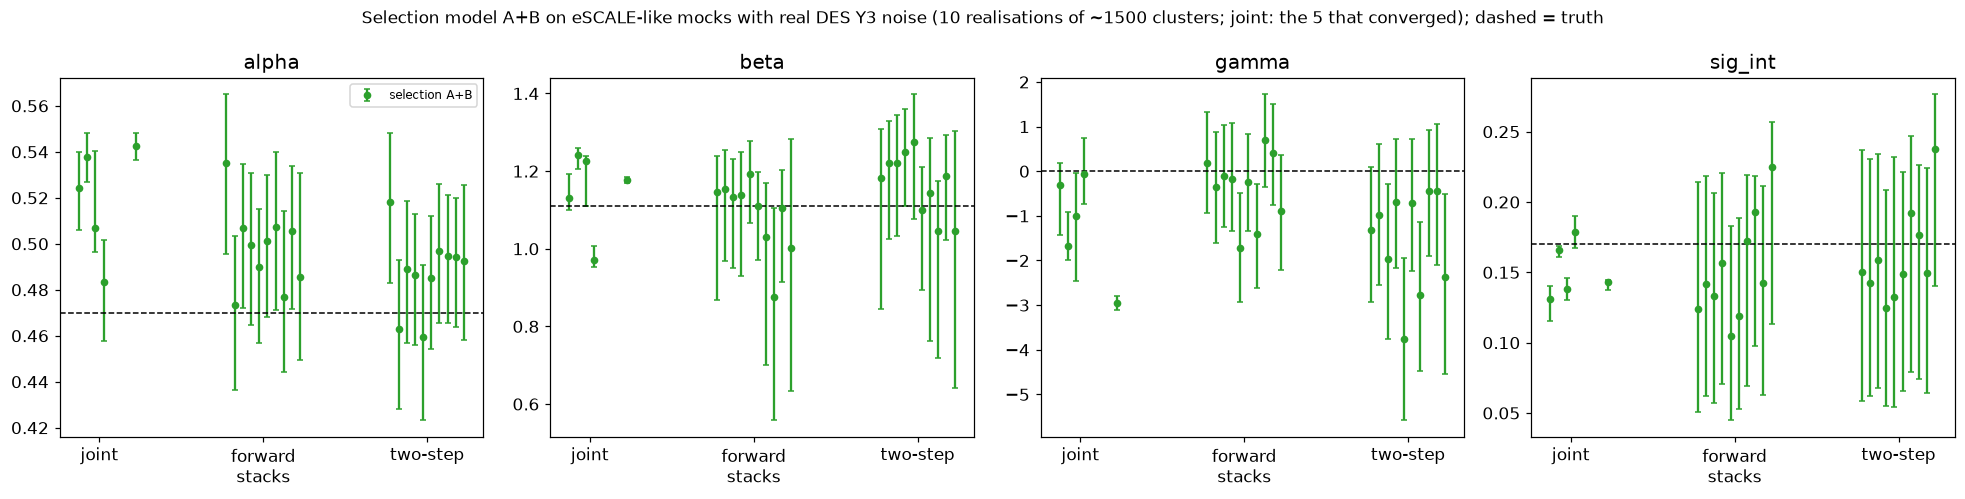

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
cols = {'AB': 'C2'}
labs = {'det': 'deterministic', 'A': 'selection A (X-ray only)', 'AB': 'selection A+B'}
xpos = {'joint': 0, 'forward': 1, 'twostep': 2}
off = {'AB': 0.0}
for a, p in zip(ax, ['alpha', 'beta', 'gamma', 'sig_int']):
    seen = set()
    for fw, s, sd, r in rows:
        if p not in r: continue
        x = xpos[fw] + off[s] + 0.05 * (sd - np.mean(seeds))
        a.errorbar(x, r[p][1], yerr=[[r[p][1] - r[p][0]], [r[p][2] - r[p][1]]], fmt='o', color=cols[s], ms=4, capsize=2,
                   label=labs[s] if s not in seen else None); seen.add(s)
    a.axhline(TRUTH[p], color='k', ls='--', lw=1)
    a.set_xticks([0, 1, 2]); a.set_xticklabels(['joint', 'forward\nstacks', 'two-step']); a.set_title(p)
ax[0].legend(fontsize=8)
fig.suptitle(f'Selection model A+B on eSCALE-like mocks with real DES Y3 noise ({len(seeds)} realisations of ~1500 clusters; joint: the 5 that converged); dashed = truth', fontsize=11)
plt.tight_layout(); plt.show()

## 2 — Real data

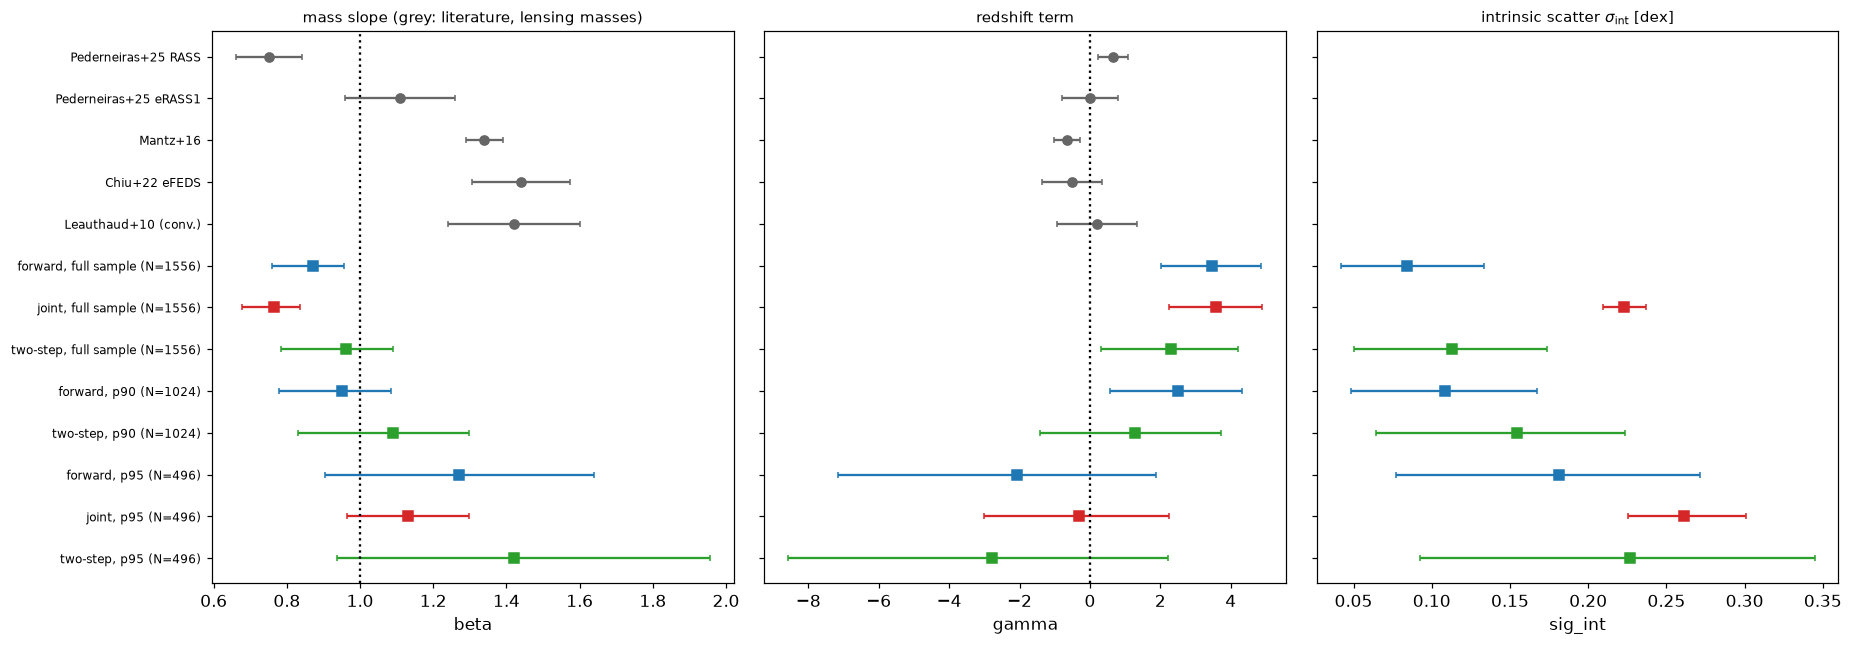

In [4]:
lit = [('Pederneiras+25 RASS', 0.75, 0.09, 0.65, 0.43), ('Pederneiras+25 eRASS1', 1.11, 0.15, 0.00, 0.79),
       ('Mantz+16', 1.34, 0.05, -0.65, 0.38), ('Chiu+22 eFEDS', 1.44, 0.135, -0.51, 0.84), ('Leauthaud+10 (conv.)', 1.42, 0.18, 0.20, 1.14)]
keys = list(real.keys())
fig, ax = plt.subplots(1, 3, figsize=(17, 6), sharey=True)
y = np.arange(len(lit) + len(keys))[::-1]
for a, p in zip(ax, ['beta', 'gamma', 'sig_int']):
    for k, l in enumerate(lit):
        if p == 'beta': a.errorbar(l[1], y[k], xerr=l[2], fmt='o', color='0.4', capsize=2)
        if p == 'gamma': a.errorbar(l[3], y[k], xerr=l[4], fmt='o', color='0.4', capsize=2)
    for k, key in enumerate(keys):
        r = real[key]
        if p not in r: continue
        c = {'forward': 'C0', 'joint': 'C3', 'two-step': 'C2'}[key.split(',')[0]]
        a.errorbar(r[p][1], y[len(lit) + k], xerr=[[r[p][1] - r[p][0]], [r[p][2] - r[p][1]]], fmt='s', color=c, capsize=2)
    a.set_xlabel(p)
ax[0].axvline(1, color='k', ls=':'); ax[1].axvline(0, color='k', ls=':')
ax[0].set_yticks(y); ax[0].set_yticklabels([l[0] for l in lit] + keys, fontsize=8)
ax[0].set_title('mass slope (grey: literature, lensing masses)', fontsize=10); ax[1].set_title('redshift term', fontsize=10)
ax[2].set_title(r'intrinsic scatter $\sigma_{\rm int}$ [dex]', fontsize=10)
plt.tight_layout(); plt.show()

## 3 — Reading the results

### Mocks (A+B)

Entries are the mean over realisations ± the error of that mean; the truth is α 0.47, β 1.11, γ 0, σ_int 0.17, f_mis 0.30.

| Framework | N mocks | α | β | γ | σ_int | f_mis |
|---|---|---|---|---|---|---|
| forward stacks | 10 | 0.498 ± 0.006 | 1.089 ± 0.030 | −0.36 ± 0.24 | 0.151 ± 0.012 | 0.31 ± 0.02 |
| two-step | 10 | 0.488 ± 0.005 | 1.167 ± 0.026 | −1.55 ± 0.36 | 0.161 ± 0.010 | — |
| joint | 5 | 0.519 ± 0.011 | 1.15 ± 0.05 | −1.2 ± 0.5 | 0.151 ± 0.009 | 0.47 ± 0.02 |

* **Forward-modelled stacks** recover β, γ, σ_int and f_mis. A residual α offset of +0.03 is probably the bin-centre model evaluation; paper 1.1 found a −0.018 dex mass offset from it.
* **Two-step** biases γ low. Comparing a single-halo stack mass with the predicted mean stack mass is too crude for the redshift term.
* **Joint fit on the mocks:**
  * Only 5 of 10 realisations converged.
  * Posteriors were about 4× narrower than the scatter between realisations, and f_mis came out high.
  * The cause is a mock artefact. A likelihood slice on mock 1 is jagged by tens of ln L units. On the real data (full and p95) the same slice is smooth, varying by less than 0.3 ln L.
  * Explanation: the mock's flux errors do not grow with flux, so bright mock clusters reach S/N of several hundred, and the 12-node quadrature over $\sigma_{\rm int}$ cannot resolve their narrow flux likelihood. Real eSCALE S/N stays below ~30.
  * The joint mock test therefore needs a realistic flux-error model before it says anything about the real-data joint fit.

### Real data (A+B)

| Sample | Forward stacks: β | Forward stacks: γ | Joint: β | Joint: γ |
|---|---|---|---|---|
| full (1556) | 0.87 +0.09/−0.11 | +3.5 ± 1.4 | 0.77 +0.07/−0.09 | +3.6 ± 1.3 |
| p90 (1024) | 0.95 +0.13/−0.17 | +2.5 ± 1.9 | 0.81 +0.06/−0.09 (b) | +2.4 +1.4/−1.5 (b) |
| p95 (496) | 1.27 ± 0.37 | −2.1 +4.0/−5.1 | 1.16 +0.09/−0.14 (b) | −0.2 +2.3/−2.8 (b) |

* With increasing purity, β rises towards the lensing-calibrated literature (Pederneiras+25 eRASS1: 1.11 ± 0.15) and γ falls towards zero. That is the pattern contamination of the lower-purity matches would produce. Neighbouring rows differ within their errors, so it is a consistent trend, not a significant one.
* Forward stacks and the joint fit agree on every sample.
* (b): median and 16–84% range of 50 cluster-bootstrap medians (§4). The bootstrap spread is 0.7–1.1 times the single-fit posterior widths, so on real data the joint posteriors are not too narrow, consistent with the smooth real-data likelihood.
* In the joint fit, β goes from 0.77 (full) to 0.81 (p90) to 1.16 (p95). p95 is a subset of p90, so the samples are correlated. The p90-to-p95 step suggests much of the contamination sits in the 528 clusters flagged at 90% but not 95% purity.

## 4 — Joint fit: cluster bootstraps (p95, p90)

50 resamples of the clusters with replacement (seed 7000 + b), each refitted with the joint A+B likelihood, as in paper 1.1's `joint_sh.py`. Below: the median and 16–84% range of the per-bootstrap medians, and the ratio of that spread to the typical single-fit posterior width.

In [5]:
for sub in ['p95', 'p90']:
    fs = sorted(glob.glob(f'{FS}/joint_AB_{sub}_b*.npz'))
    B = [q_npz(f) for f in fs]
    print(f'joint A+B, {sub}: {len(B)} bootstraps')
    for p in PAR:
        meds = np.array([b[p][1] for b in B]); lo, me, hi = np.percentile(meds, [16, 50, 84])
        pw = np.median([(b[p][2] - b[p][0]) / 2 for b in B])
        print(f'  {p:9s} {me:+.3f} +{hi-me:.3f}/-{me-lo:.3f}   spread/posterior width = {((hi-lo)/2)/pw:.1f}')

joint A+B, p95: 50 bootstraps
  alpha     -0.040 +0.058/-0.069   spread/posterior width = 1.1
  beta      +1.161 +0.089/-0.139   spread/posterior width = 0.7
  gamma     -0.194 +2.315/-2.777   spread/posterior width = 1.0
  sig_int   +0.258 +0.035/-0.039   spread/posterior width = 0.9
  f_mis     +0.687 +0.114/-0.132   spread/posterior width = 0.8
  sigma_off +0.193 +0.055/-0.030   spread/posterior width = 0.9


joint A+B, p90: 50 bootstraps
  alpha     +0.131 +0.037/-0.039   spread/posterior width = 1.1
  beta      +0.806 +0.062/-0.088   spread/posterior width = 0.7
  gamma     +2.383 +1.360/-1.534   spread/posterior width = 0.9
  sig_int   +0.225 +0.019/-0.017   spread/posterior width = 1.0
  f_mis     +0.525 +0.189/-0.116   spread/posterior width = 1.1
  sigma_off +0.223 +0.136/-0.057   spread/posterior width = 1.3
